In [ ]:
import cobra
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import pickle
import sys
from scipy.stats import spearmanr
sys.path.append('../../')
from helper_function import *
cobra.Configuration.solver = 'glpk'

In [ ]:
with open('../../Coarse_graining_result/clustered_nodes_c20_s44_pq1_relabeled.pkl', 'rb') as f:
    cluster_nodes = pickle.load(f)

gem2seed = pd.read_csv('../../Expression_datasets/model_reaction_to_seed_reaction_mapping.csv')
Ecoli = cobra.io.load_json_model('../../Expression_datasets/palsson_nc/iML1515.json')

In [4]:
Ecoli_gpr = []
for rec in Ecoli.reactions:

    seedrec = rec.annotation.get('seed.reaction')
    if seedrec is None:
        continue

    seedrec = seedrec[0]

    if len(rec.genes) > 0:
        gene_id = [gene.id for gene in list(rec.genes) if gene.id not in ['Unknown']]
        Ecoli_gpr.append((seedrec, gene_id))
Ecoli_gpr = pd.DataFrame(Ecoli_gpr, columns=['Model_Reaction_ID', 'Gene_IDs'])

In [5]:
cluster_genes = {}
for idx, group in cluster_nodes.items():
    for rec in group:
        rec2seed = gem2seed[gem2seed['Model_Reaction_ID'] == rec[:-4]]['SEED_Reaction_ID'].values
        rec2seed = rec2seed[0] if len(rec2seed) > 0 else None
        if rec2seed is not None:
            rec2gene = Ecoli_gpr[Ecoli_gpr['Model_Reaction_ID'] == rec2seed]['Gene_IDs'].values
            rec2gene = rec2gene[0] if len(rec2gene) > 0 else None
            if rec2gene is not None:
                if idx not in cluster_genes:
                    cluster_genes[idx] = []
                for gene in rec2gene:
                    cluster_genes[idx].append(gene)

In [6]:
Ecoli_trans_data = pd.read_excel('../../Expression_datasets/palsson_nc/palsson_nc.xlsx', sheet_name='Expression Data')
gr = pd.read_excel('../../Expression_datasets/palsson_nc/palsson_nc.xlsx', sheet_name='Metadata')['Growth Rate (1/hr)']
pH = pd.read_excel('../../Expression_datasets/palsson_nc/palsson_nc.xlsx', sheet_name='Metadata')['pH']
antibiotic = pd.read_excel('../../Expression_datasets/palsson_nc/palsson_nc.xlsx', sheet_name='Metadata')['Antibiotic']
gene_classification = pd.read_excel('../../Expression_datasets/hwa_pnas/gene_classification.xlsx', sheet_name='Ecoli')

In [7]:
# index = (gr.notna()) & (gr > 0.0)
index = (gr.notna()) & (gr > 0.2) & (gr < 1.3) & (pH == 7) & (antibiotic.isna())
gr = gr[index]
id_col = Ecoli_trans_data.iloc[:, 0]
Ecoli_tpm = 2 ** Ecoli_trans_data.iloc[:, 1:] - 1
Ecoli_trans_data = Ecoli_tpm / Ecoli_tpm.sum(axis=0)
Ecoli_trans_data = Ecoli_trans_data.loc[:, index.values]
Ecoli_trans_data = pd.concat([id_col, Ecoli_trans_data], axis=1)

In [ ]:
r_sector_genes = np.array(gene_classification[gene_classification['level 1'].isin(['Translation', 'Transcription'])]['gene locus'])

r_sector_genes_expression = np.zeros(Ecoli_trans_data.shape[1] - 1)

for gene in r_sector_genes:

        gene_value = Ecoli_trans_data[Ecoli_trans_data['log-TPM'] == gene].iloc[:, 1:].values

        if gene_value.size == 0:
            continue

        gene_value = np.array(gene_value[0])

        r_sector_genes_expression += gene_value


In [ ]:
n_samples = Ecoli_trans_data.shape[1] - 1
overall_value = np.zeros((len(cluster_nodes), n_samples)) 

for idx, group in cluster_genes.items():

    group_value = np.zeros(n_samples)

    for gene in group:

        gene_count = sum(gene in g for g in cluster_genes.values())

        gene_value = Ecoli_trans_data[Ecoli_trans_data['log-TPM'] == gene].iloc[:, 1:].values

        if gene_value.size == 0:
            continue


        gene_value = np.array(gene_value[0]) / gene_count


        group_value += gene_value


    overall_value[idx, :] = group_value

norm_overall_value = overall_value / np.sum(overall_value, axis=0)

Cluster 0: Spearman rho = -0.239, p-value = 5.943e-03
Cluster 1: Spearman rho = -0.406, p-value = 1.485e-06
Cluster 2: Spearman rho = -0.057, p-value = 5.190e-01
Cluster 3: Spearman rho = -0.690, p-value = 7.893e-20
Cluster 4: Spearman rho = 0.382, p-value = 6.721e-06
Cluster 5: Spearman rho = -0.485, p-value = 4.270e-09
Cluster 6: Spearman rho = -0.598, p-value = 4.504e-14
Cluster 7: Spearman rho = 0.257, p-value = 3.026e-03
Cluster 8: Spearman rho = -0.651, p-value = 3.630e-17
Cluster 9: Spearman rho = -0.291, p-value = 7.475e-04
Cluster 10: Spearman rho = 0.192, p-value = 2.842e-02
Cluster 11: Spearman rho = 0.203, p-value = 1.989e-02
Cluster 12: Spearman rho = 0.570, p-value = 1.262e-12
Cluster 13: Spearman rho = 0.523, p-value = 1.424e-10
Cluster 14: Spearman rho = -0.021, p-value = 8.109e-01
Cluster 15: Spearman rho = -0.329, p-value = 1.269e-04
Cluster 16: Spearman rho = 0.160, p-value = 6.870e-02
Cluster 17: Spearman rho = 0.540, p-value = 2.694e-11
Cluster 18: Spearman rho = -

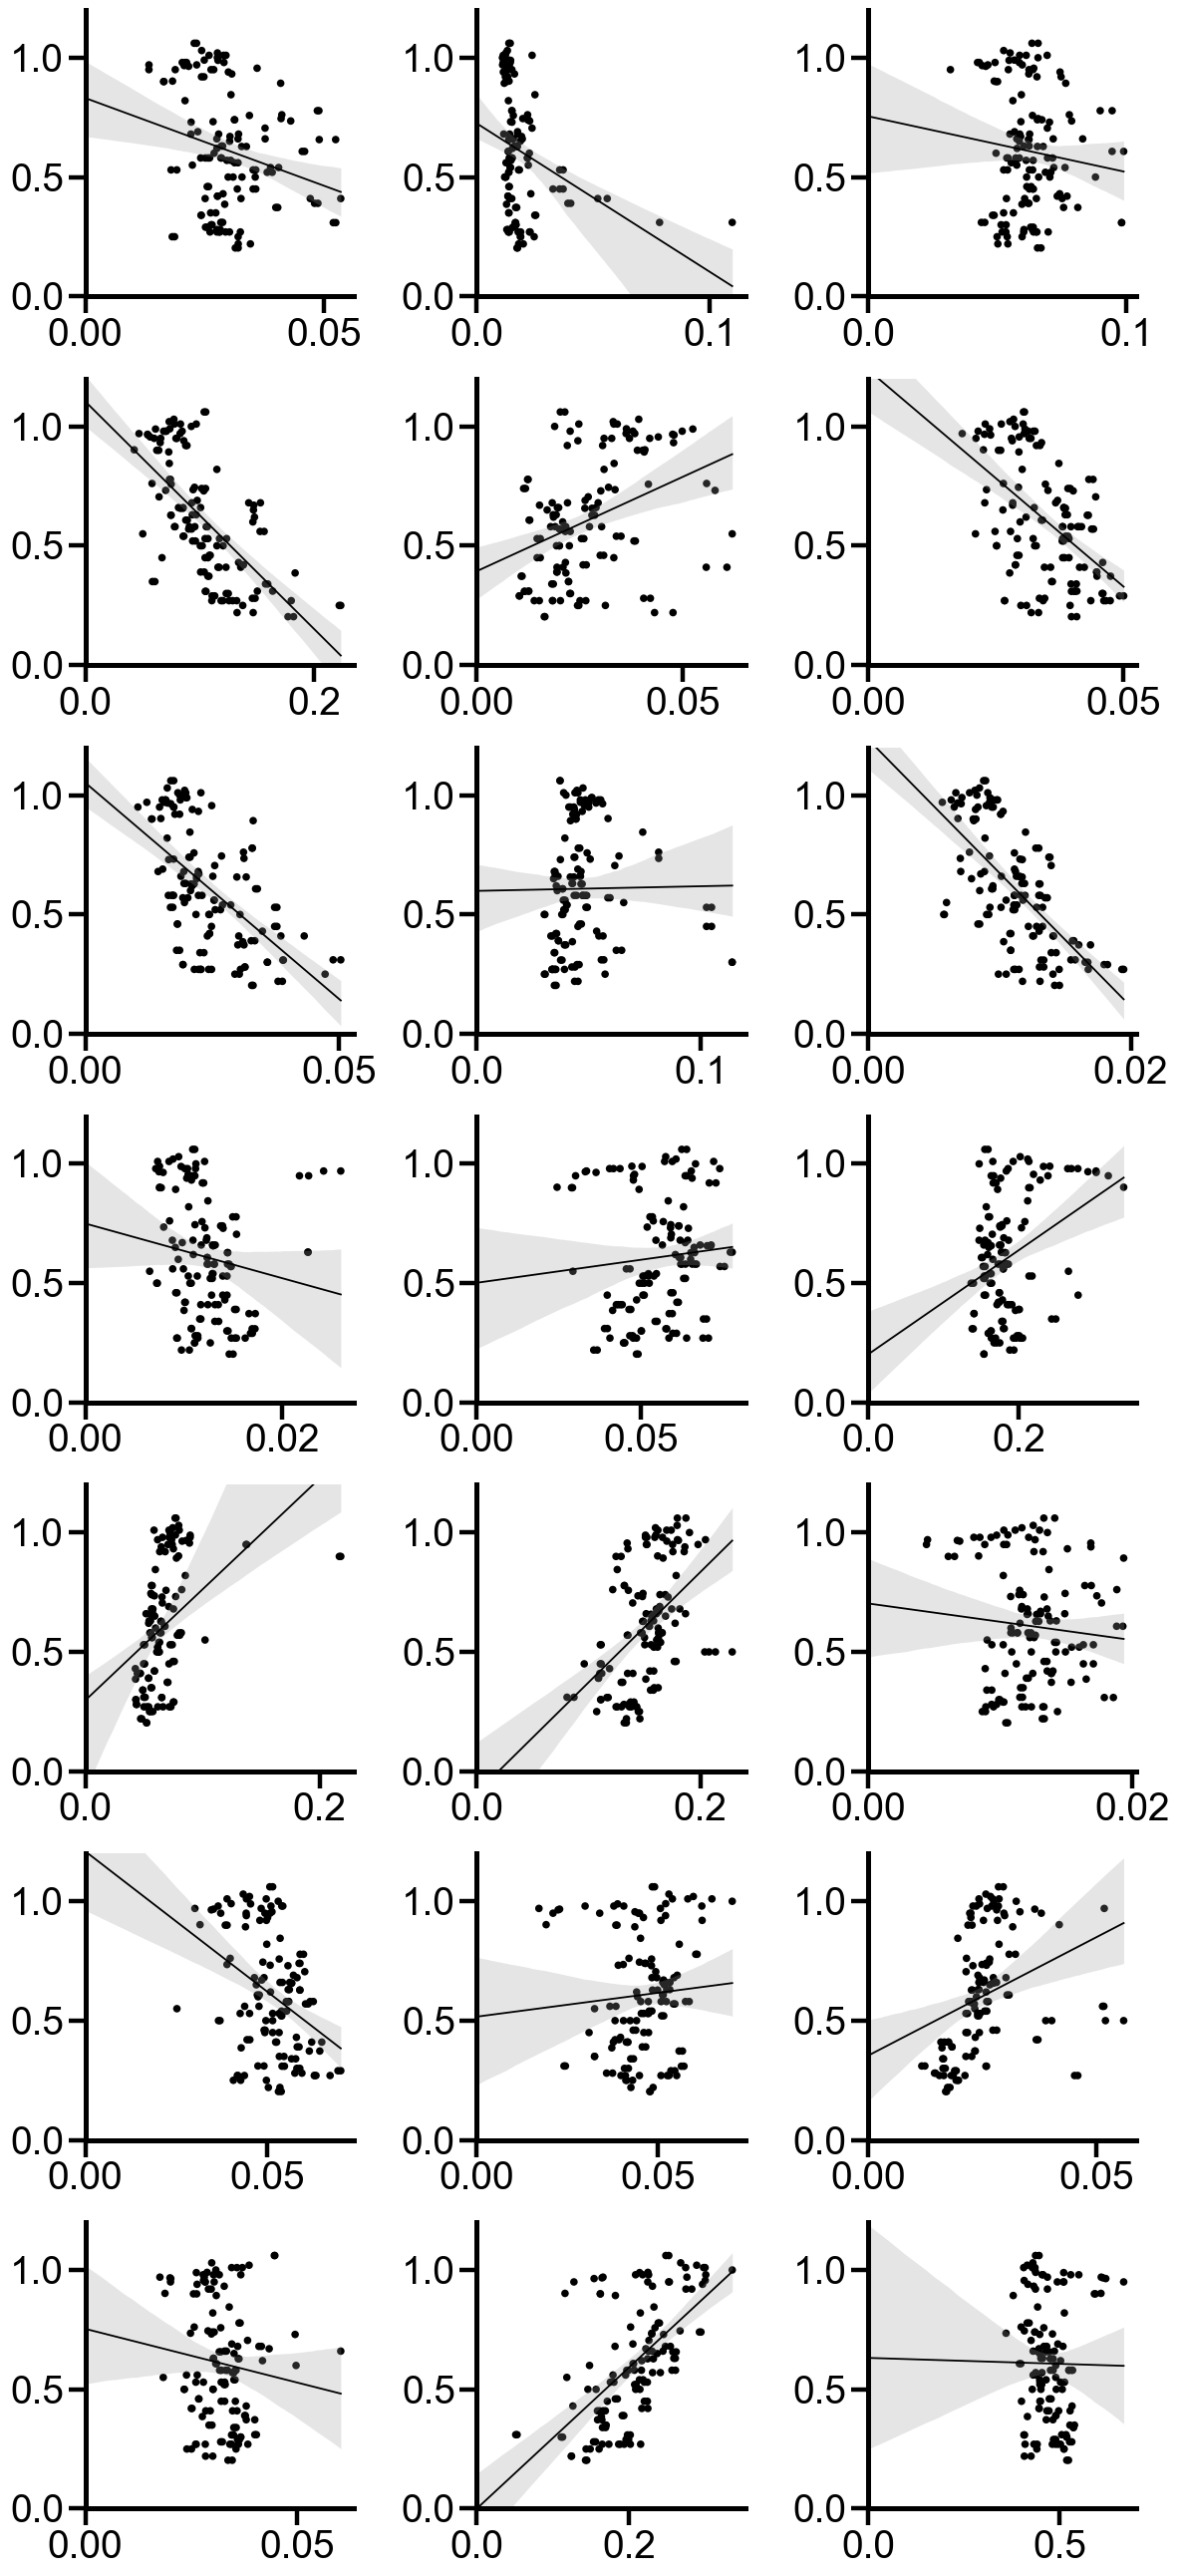

In [ ]:
set_panel_style(scale=4)

plt.rcParams['font.family'] = 'Arial'
plt.rcParams['font.size'] = 12

corr_harris = []


fig, axes = plt.subplots(7, 3, figsize=(12, 26))
axes = axes.flatten()

point_rgb = (0.0, 0.0, 0.0)
line_rgb  = (0.0, 0.0, 0.0)
band_rgb  = (0.6, 0.6, 0.6)

corr_harris = []

rng = np.random.default_rng(0)
y_all = gr.to_numpy(dtype=float)

for i in range(21):

    ax = axes[i]


    if i == 19:
        x = r_sector_genes_expression
    elif i == 20:
        x = overall_value.sum(axis=0)
    else:
        x = norm_overall_value[i].astype(float)

    
    valid = np.isfinite(x) & np.isfinite(y_all)

    x = x[valid]
    y = y_all[valid]

    rho, p = spearmanr(x, y)
    print((f"Cluster {i}: Spearman rho = {rho:.3f}, p-value = {p:.3e}"))

    # ---------- OLS ----------
    m, b = np.polyfit(x, y, deg=1)

    xg = np.linspace(0, x.max(), 200)
    yg = m * xg + b

    # ---------- bootstrap CI ----------
    B = 2000
    n = x.size
    Yhat = np.full((B, xg.size), np.nan)

    for j in range(B):
        idx = rng.integers(0, n, n)
        x_boot = x[idx]
        y_boot = y[idx]

        if np.unique(x_boot).size < 2:
            continue

        m_i, b_i = np.polyfit(x_boot, y_boot, deg=1)
        Yhat[j] = m_i * xg + b_i

    lo, hi = np.nanpercentile(Yhat, [2.5, 97.5], axis=0)

    # ---------- plot ----------
    ax.scatter(
        x, y,
        s=30,
        color=point_rgb,
        edgecolors="none"
    )

    ax.plot(
        xg, yg,
        linewidth=1.3,
        color=line_rgb
    )

    ax.fill_between(
        xg, lo, hi,
        alpha=0.25,
        color=band_rgb,
        linewidth=0
    )

    #ax.set_xlabel(f"E_{i}")

    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)


    ax.set_xlim(0, 1.05 * x.max())
    ax.set_ylim(0, 1.2)



plt.tight_layout(w_pad=1.5, h_pad=1.5)
#fig.savefig(f"Supp_Figure6a.pdf", format="pdf", bbox_inches="tight", pad_inches=0.5)
plt.show()